In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

### Section 0: Some more preprocessing for training models

In [2]:
# phần code để gọi dữ liệu
data = pd.read_csv('data/flight_delay_preprocessed.csv')
data.describe()

,MONTH,DISTANCE,DELAYED,DAY_OF_WEEK_sin,DAY_OF_WEEK_cos,DEP_HOUR_sin,DEP_HOUR_cos,ARR_HOUR_sin,ARR_HOUR_cos,AIRLINE_AA,...,DESTINATION_AIRPORT_LAX,DESTINATION_AIRPORT_LGA,DESTINATION_AIRPORT_MCO,DESTINATION_AIRPORT_MSP,DESTINATION_AIRPORT_ORD,DESTINATION_AIRPORT_Other,DESTINATION_AIRPORT_PHX,DESTINATION_AIRPORT_SEA,DESTINATION_AIRPORT_SFO,DESTINATION_AIRPORT_SLC
count,245486.000000,245486.000000,245486.000000,2.454860e+05,245486.000000,245486.000000,2.454860e+05,245486.000000,245486.000000,245486.000000,...,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000,245486.000000
mean,6.560305,822.787906,0.230665,1.517582e-02,-0.025220,-0.086936,-3.766079e-01,-0.270139,-0.258586,0.124924,...,0.032845,0.016286,0.020140,0.019541,0.048561,0.491881,0.025460,0.019081,0.025358,0.016885
std,3.396686,606.326847,0.421259,7.074254e-01,0.706178,0.751046,5.352956e-01,0.656390,0.655220,0.330633,...,0.178231,0.126574,0.140478,0.138416,0.214948,0.499935,0.157517,0.136808,0.157210,0.128840
min,1.000000,31.000000,0.000000,-9.749279e-01,-0.900969,-1.000000,-1.000000e+00,-1.000000,-1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,373.000000,0.000000,-7.818315e-01,-0.900969,-0.866025,-8.660254e-01,-0.866025,-0.866025,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.000000,649.000000,0.000000,-2.449294e-16,-0.222521,-0.258819,-5.000000e-01,-0.500000,-0.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.000000,1062.000000,0.000000,7.818315e-01,0.623490,0.707107,6.123234e-17,0.258819,0.258819,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,12.000000,4983.000000,1.000000,9.749279e-01,1.000000,1.000000,1.000000e+00,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [3]:
X = data.drop(columns="DELAYED")
y = data["DELAYED"].to_numpy()
# phân tách dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42 # 80/20 split
)
# chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[["DISTANCE"]] = scaler.fit_transform(X_train[["DISTANCE"]])
X_test[["DISTANCE"]] = scaler.transform(X_test[["DISTANCE"]])

# convert to numpy
X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)

### Section 1: Logistic Regression

In [4]:
# 1. Test in the scratch model
from model.LogisticRegression import LogisticRegressionScratch
eta = 0.0005
model_scratch = LogisticRegressionScratch(eta=eta, max_iter=20, tol=0,
                                          class_weight="balanced") # sửa để match với mode trong sklearn

model_scratch.fit(X_train_np, y_train)
test_prob = model_scratch.predict_proba(X_test_np)

print(test_prob)
# print(X_train.describe().loc[["min", "max"]].T.sort_values("max", ascending=False).head(5))
# print(model_scratch.loss_history)

[0.49021701 0.62822821 0.48702928 ... 0.2964516  0.4092552  0.47578298]


In [5]:
# in thông số
def evaluate(name, y_true, proba, threshold=0.5, eta=None):
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "eta": eta,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
    }

print(pd.DataFrame([evaluate("model_scratch", y_test, test_prob, eta=eta)]))
print(f"Confusion matrix of Logistic Regression from Scratch:\n  1       0\n{confusion_matrix(y_test, (test_prob >= 0.5).astype(int))}")

           model     eta  accuracy  precision    recall        f1
0  model_scratch  0.0005  0.527577   0.285104  0.695276  0.404386
Confusion matrix of Logistic Regression from Scratch:
  1       0
[[18029 19744]
 [ 3451  7874]]


Training with eta = 0.00025 ...
           model      eta  accuracy  precision    recall        f1
0  model_scratch  0.00025  0.552568   0.291583  0.657395  0.403983
Training with eta = 0.0005 ...
           model     eta  accuracy  precision    recall        f1
0  model_scratch  0.0005  0.527577   0.285104  0.695276  0.404386
Training with eta = 0.001 ...
           model    eta  accuracy  precision    recall        f1
0  model_scratch  0.001  0.505418    0.27985  0.727241  0.404171
Training with eta = 0.005 ...
           model    eta  accuracy  precision    recall        f1
0  model_scratch  0.005  0.362703   0.249038  0.874702  0.387695
Training with eta = 0.01 ...
           model   eta  accuracy  precision    recall        f1
0  model_scratch  0.01  0.290786   0.237686  0.939956  0.379426
Training with eta = 0.05 ...
           model   eta  accuracy  precision    recall        f1
0  model_scratch  0.05  0.249379   0.232585  0.980309  0.375969
Training with eta = 0.1 ...
         

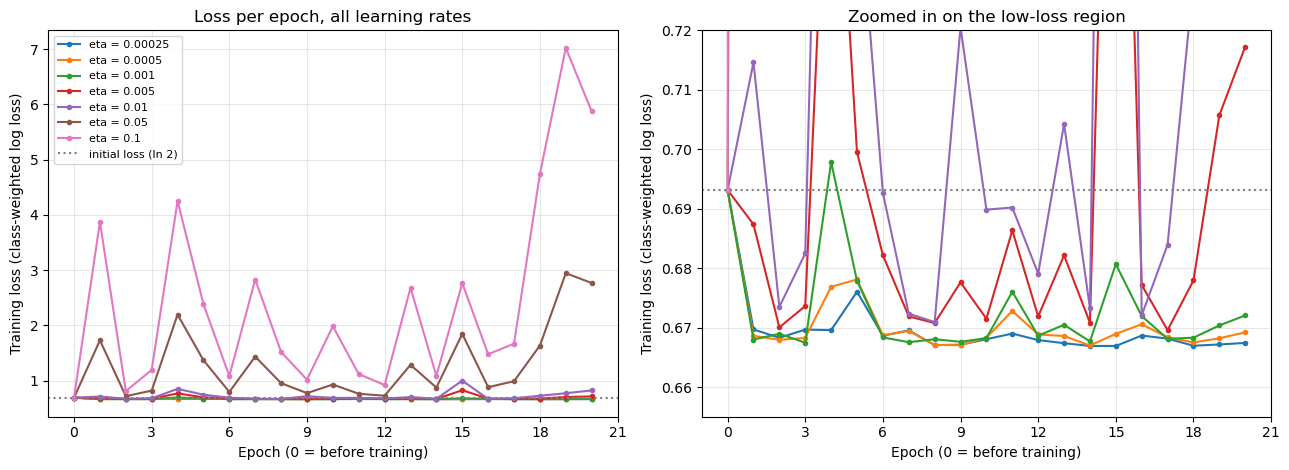

In [6]:
# in loss decay theo một vài giá trị eta
from matplotlib.ticker import MaxNLocator
ETAS = [0.00025, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]
histories = {}
for eta in ETAS:
    print(f"Training with eta = {eta} ...")
    model = LogisticRegressionScratch(eta=eta, max_iter=20, tol=0,
                                      class_weight="balanced")
    model.fit(X_train_np, y_train)
    sub_test_prob = model.predict_proba(X_test_np)
    print(pd.DataFrame([evaluate("model_scratch", y_test, sub_test_prob, eta=eta)]))
    histories[eta] = model.loss_history
 
initial_loss = next(iter(histories.values()))[0]

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.8))
 
for ax in (ax_full, ax_zoom):
    for eta, h in histories.items():
        ax.plot(range(len(h)), h, marker="o", markersize=3, label=f"eta = {eta}")
    ax.axhline(initial_loss, color="gray", linestyle=":", label="initial loss (ln 2)")
    ax.set_xlabel("Epoch (0 = before training)")
    ax.set_ylabel("Training loss (class-weighted log loss)")
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
 
ax_full.set_title("Loss per epoch, all learning rates")
ax_full.legend(fontsize=8)
 
ax_zoom.set_ylim(0.655, 0.72)
ax_zoom.set_title("Zoomed in on the low-loss region")
 
plt.tight_layout()
plt.show()

In [7]:
# Sklearn model
from sklearn.linear_model import LogisticRegression
sk_model = LogisticRegression(C=1e6, class_weight="balanced", max_iter=100) # C=1e6 để loại L2 regularization
sk_model.fit(X_train_np, y_train)
sk_prob = sk_model.predict_proba(X_test_np)[:, 1]

print(pd.DataFrame([evaluate("sk_model", y_test, sk_prob)]))
print(f"Confusion matrix of Logistic Regression from sklearn:\n  1       0\n{confusion_matrix(y_test, (sk_prob >= 0.5).astype(int))}")

      model   eta  accuracy  precision    recall        f1
0  sk_model  None   0.57538   0.297633  0.618366  0.401848
Confusion matrix of Logistic Regression from sklearn:
  1       0
[[21247 16526]
 [ 4322  7003]]


### Section 2: CART (Classification and Regression Trees)

#### 2.1 Cơ sở toán học
##### Độ tạp Gini (Gini impurity)

Đo mức độ "trộn lẫn" của các lớp tại một nút $t$:

$$G(t) = 1 - \sum_{k=1}^{K} p_k^2$$

- $p_k$: tỉ lệ mẫu thuộc lớp $k$ tại nút $t$.
- $G=0$ khi nút **thuần** (chỉ một lớp); $G$ lớn nhất $1 - 1/K$ khi các lớp phân bố đều.

##### Độ lợi Gini (Gini gain) khi chia nút

Chia nút $t$ thành con trái $L$ và con phải $R$:

$$\Delta G = G(t) - \left( \frac{|L|}{|t|} G(L) + \frac{|R|}{|t|} G(R) \right)$$

CART chọn đặc trưng $j^*$ và ngưỡng $s^*$ làm **cực đại** độ lợi:

$$(j^*, s^*) = \arg\max_{j,s} \Delta G(j,s), \qquad L=\{x: x_j \le s\},\ R=\{x: x_j > s\}$$

Trong bài toán này, dữ liệu mất cân bằng nên mô hình dùng `class_weight="balanced"`. Khi đó, Gini được tính theo trọng số lớp để giảm xu hướng ưu tiên lớp chiếm đa số.


#### Huấn luyện CART tự cài đặt



In [8]:
import numpy as np
import pandas as pd

# Đọc dữ liệu (sửa lại đường dẫn nếu cần)
DATA_PATH = r"./data/flight_delay_preprocessed.csv"

df = pd.read_csv(DATA_PATH)

# Tách nhãn (cột DELAYED) và đặc trưng (các cột còn lại)
y = df["DELAYED"].values.astype(int)          # nhãn: 0 = đúng giờ, 1 = trễ
X = df.drop(columns=["DELAYED"]).values.astype(float)   # ma trận đặc trưng
feature_names = list(df.drop(columns=["DELAYED"]).columns)  # tên các cột

print("Số mẫu:", X.shape[0], "| Số đặc trưng:", X.shape[1])
print("Phân bố nhãn (0=đúng giờ, 1=trễ):", dict(zip(*np.unique(y, return_counts=True))))

Số mẫu: 245486 | Số đặc trưng: 64
Phân bố nhãn (0=đúng giờ, 1=trễ): {np.int64(0): np.int64(188861), np.int64(1): np.int64(56625)}


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import importlib
from model import CART

# Nạp lại module để dùng phiên bản CART.py có hỗ trợ class_weight.
importlib.reload(CART)
DecisionTree = CART.DecisionTree

X_train_cart, X_test_cart, y_train_cart, y_test_cart = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# CART không cần chuẩn hóa đặc trưng
cart_model = DecisionTree(min_samples_split=2, max_depth=10, class_weight="balanced")
cart_model.fit(X_train_cart, y_train_cart, feature_names=feature_names)
cart_pred = cart_model.predict(X_test_cart)

cart_metrics = {
    "model": "CART from scratch",
    "accuracy": accuracy_score(y_test_cart, cart_pred),
    "precision": precision_score(y_test_cart, cart_pred, zero_division=0),
    "recall": recall_score(y_test_cart, cart_pred, zero_division=0),
    "f1": f1_score(y_test_cart, cart_pred, zero_division=0),
}

print(pd.DataFrame([cart_metrics]))
print("Confusion matrix of CART from scratch (rows = true labels, columns = predicted labels; order: 0, 1):")
print(confusion_matrix(y_test_cart, cart_pred, labels=[0, 1]))
print(f"Tree depth: {cart_model.get_depth()} | Leaves: {cart_model.get_n_leaves()}")

               model  accuracy  precision    recall        f1
0  CART from scratch  0.560064   0.296155  0.659073  0.408673
Confusion matrix of CART from scratch (rows = true labels, columns = predicted labels; order: 0, 1):
[[20034 17739]
 [ 3861  7464]]
Tree depth: 10 | Leaves: 778


#### So sánh với CART trong scikit-learn

Huấn luyện `DecisionTreeClassifier` với cùng `max_depth`, `class_weight` và tập train/test để đối chiếu kết quả.

In [10]:
from sklearn.tree import DecisionTreeClassifier

sk_cart = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
)
sk_cart.fit(X_train_cart, y_train_cart)
sk_cart_pred = sk_cart.predict(X_test_cart)

cart_comparison = pd.DataFrame([
    cart_metrics,
    {
        "model": "scikit-learn CART",
        "accuracy": accuracy_score(y_test_cart, sk_cart_pred),
        "precision": precision_score(y_test_cart, sk_cart_pred, zero_division=0),
        "recall": recall_score(y_test_cart, sk_cart_pred, zero_division=0),
        "f1": f1_score(y_test_cart, sk_cart_pred, zero_division=0),
    },
])
print(cart_comparison)
print("Confusion matrix of scikit-learn CART (rows = true labels, columns = predicted labels; order: 0, 1):")
print(confusion_matrix(y_test_cart, sk_cart_pred, labels=[0, 1]))

               model  accuracy  precision    recall        f1
0  CART from scratch  0.560064   0.296155  0.659073  0.408673
1  scikit-learn CART  0.580716   0.301751  0.622340  0.406436
Confusion matrix of scikit-learn CART (rows = true labels, columns = predicted labels; order: 0, 1):
[[21464 16309]
 [ 4277  7048]]


max_depth  train_f1  validation_f1  validation_recall  validation_accuracy
        1    0.3944         0.3941             0.6487               0.5399
        2    0.3944         0.3941             0.6487               0.5399
        3    0.3807         0.3782             0.4719               0.6421
        5    0.4080         0.4064             0.6534               0.5597
        8    0.4219         0.4091             0.6301               0.5801
       12    0.4497         0.4049             0.6104               0.5862
       15    0.4866         0.3975             0.5898               0.5875
       20    0.5773         0.3822             0.5385               0.5984
unlimited    0.9732         0.2983             0.3062               0.6678
Best setting by validation F1: max_depth=8, F1=0.4091, recall=0.6301


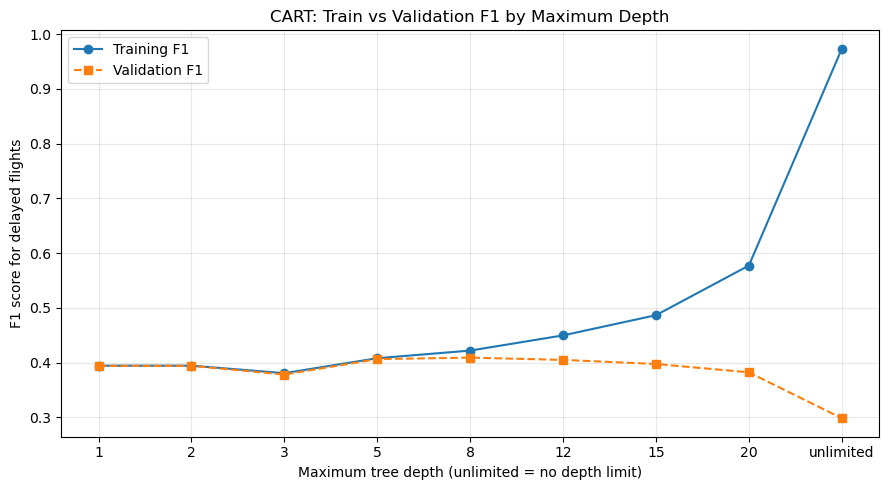

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier

# Tách validation từ tập train, giữ riêng test set để đánh giá cuối cùng.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_cart, y_train_cart, test_size=0.2, stratify=y_train_cart, random_state=42
)

# None nghĩa là không giới hạn max_depth.
MAX_DEPTHS = [1, 2, 3, 5, 8, 12, 15, 20, None]
results = []

for depth in MAX_DEPTHS:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_split=2,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X_fit, y_fit)
    train_pred = model.predict(X_fit)
    val_pred = model.predict(X_val)

    results.append({
        "max_depth": "unlimited" if depth is None else depth,
        "train_f1": f1_score(y_fit, train_pred, zero_division=0),
        "validation_f1": f1_score(y_val, val_pred, zero_division=0),
        "validation_recall": recall_score(y_val, val_pred, zero_division=0),
        "validation_accuracy": accuracy_score(y_val, val_pred),
    })

results = pd.DataFrame(results)
print(results.round(4).to_string(index=False))

# Chọn độ sâu theo F1 validation; không dùng test set để chọn mô hình.
best_result = results.loc[results["validation_f1"].idxmax()]
print(
    f"Best setting by validation F1: max_depth={best_result['max_depth']}, "
    f"F1={best_result['validation_f1']:.4f}, "
    f"recall={best_result['validation_recall']:.4f}"
)

# So sánh train và validation f1 để nhận biết overfitting.
fig, ax = plt.subplots(figsize=(9, 5))
x_positions = np.arange(len(results))
ax.plot(x_positions, results["train_f1"], marker="o", label="Training F1")
ax.plot(x_positions, results["validation_f1"], marker="s", linestyle="--", label="Validation F1")
ax.set_xticks(x_positions, results["max_depth"].astype(str))
ax.set_xlabel("Maximum tree depth (unlimited = no depth limit)")
ax.set_ylabel("F1 score for delayed flights")
ax.set_title("CART: Train vs Validation F1 by Maximum Depth")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Section 3: Random Forest

In [12]:
# Test the scratch model
from model.RandomForest import RandomForestScratch

rf = RandomForestScratch(n_estimators=100, max_depth=12, min_samples_leaf=30,
                         class_weight="balanced", oob_score=True)
rf.fit(X_train_np, y_train)
rf_prob = rf.predict_proba(X_test_np)
print(pd.DataFrame([evaluate("rf_scratch", y_test, rf_prob)]))

        model   eta  accuracy  precision  recall       f1
0  rf_scratch  None  0.588761   0.307143  0.6234  0.41153


In [13]:
# Comparison for each different amount of trees
rows = []
for t, proba in enumerate(rf.staged_predict_proba(X_test_np), start=1):
    r = evaluate(f"{t} trees", y_test, proba)
    r["n_trees"] = t
    rows.append(r)
tree_results = pd.DataFrame(rows).drop(columns=["model", "eta"], errors="ignore")
tree_results = tree_results.set_index("n_trees")

shown = [1, 2, 5, 10, 20, 30, 50, 75, 100]
print(tree_results.loc[[t for t in shown if t in tree_results.index]].round(4))

         accuracy  precision  recall      f1
n_trees                                     
1          0.5852     0.3004  0.6009  0.4006
2          0.5884     0.3034  0.6050  0.4041
5          0.5927     0.3069  0.6086  0.4080
10         0.5889     0.3055  0.6143  0.4080
20         0.5855     0.3047  0.6221  0.4091
30         0.5840     0.3040  0.6231  0.4087
50         0.5860     0.3049  0.6214  0.4091
75         0.5866     0.3061  0.6255  0.4111
100        0.5888     0.3071  0.6234  0.4115


Sweeping max_depth ...
  max_depth = 3: validation F1 = 0.3515
  max_depth = 5: validation F1 = 0.3948
  max_depth = 8: validation F1 = 0.4073
  max_depth = 12: validation F1 = 0.4126
  max_depth = 16: validation F1 = 0.4173
  max_depth = None: validation F1 = 0.4170
           train_f1  accuracy  precision  recall      f1
max_depth                                               
3            0.3569    0.6375     0.2992  0.4259  0.3515
5            0.3967    0.5849     0.2974  0.5871  0.3948
8            0.4132    0.5819     0.3026  0.6228  0.4073
12           0.4324    0.5956     0.3103  0.6159  0.4126
16           0.4498    0.6106     0.3187  0.6045  0.4173
None         0.4838    0.6285     0.3268  0.5759  0.4170 



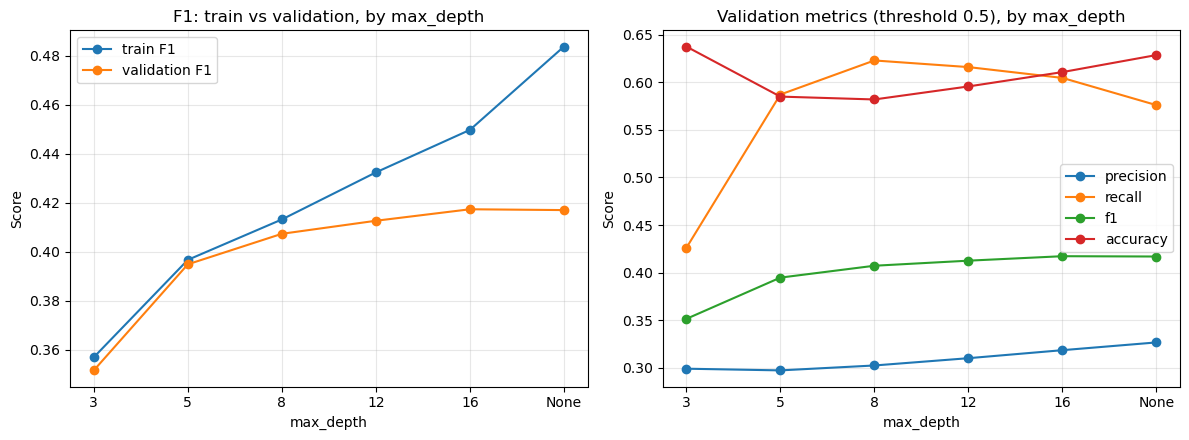

Sweeping min_samples_leaf ...
  min_samples_leaf = 5: validation F1 = 0.3748
  min_samples_leaf = 20: validation F1 = 0.4152
  min_samples_leaf = 50: validation F1 = 0.4201
  min_samples_leaf = 100: validation F1 = 0.4169
  min_samples_leaf = 300: validation F1 = 0.4108
                  train_f1  accuracy  precision  recall      f1
min_samples_leaf                                               
5                   0.7068    0.6940     0.3545  0.3977  0.3748
20                  0.5093    0.6383     0.3310  0.5566  0.4152
50                  0.4600    0.6195     0.3239  0.5976  0.4201
100                 0.4396    0.6086     0.3176  0.6065  0.4169
300                 0.4200    0.5972     0.3100  0.6088  0.4108 



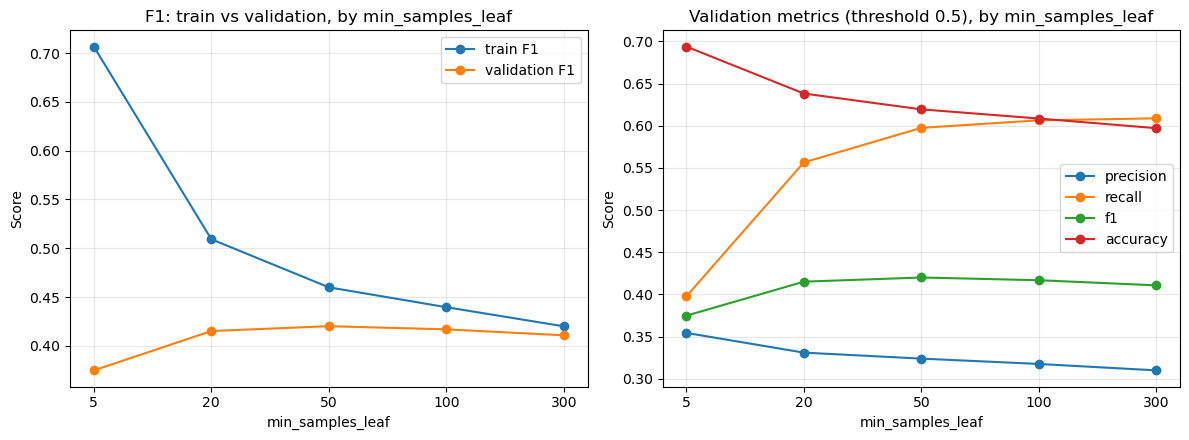

In [15]:
# Comparison for each max_depth, max_leaf value
N_TREES = 100
DEPTHS = [3, 5, 8, 12, 16, None]     # None = no depth limit
LEAVES = [5, 20, 50, 100, 300]

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_np, y_train, test_size=0.2, stratify=y_train, random_state=42) # seperate validation set

def sweep(param, values, **fixed):
    rows = []
    for v in values:
        model = RandomForestScratch(n_estimators=N_TREES, class_weight="balanced",
                                    random_state=42, **{**fixed, param: v})
        model.fit(X_fit, y_fit)
        r_tr = evaluate("train", y_fit, model.predict_proba(X_fit))
        r_val = evaluate("validation", y_val, model.predict_proba(X_val))
        rows.append({param: str(v), "train_f1": r_tr["f1"], "accuracy": r_val["accuracy"],
                     "precision": r_val["precision"], "recall": r_val["recall"], "f1": r_val["f1"]})
        print(f"  {param} = {v}: validation F1 = {r_val['f1']:.4f}")
    return pd.DataFrame(rows).set_index(param)
 
 
def plot_sweep(res, param):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    x = np.arange(len(res))
    ax1.plot(x, res["train_f1"], marker="o", label="train F1")
    ax1.plot(x, res["f1"], marker="o", label="validation F1")
    ax1.set_title(f"F1: train vs validation, by {param}")
    for col in ["precision", "recall", "f1", "accuracy"]:
        ax2.plot(x, res[col], marker="o", label=col)
    ax2.set_title(f"Validation metrics (threshold 0.5), by {param}")
    for ax in (ax1, ax2):
        ax.set_xticks(x)
        ax.set_xticklabels(res.index)
        ax.set_xlabel(param)
        ax.set_ylabel("Score")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()
 
 
# depth sweep (leaf size fixed) and leaf sweep (no depth limit, so leaf size is the only size control)
print("Sweeping max_depth ...")
depth_res = sweep("max_depth", DEPTHS, min_samples_leaf=30)
print(depth_res.round(4), "\n")
plot_sweep(depth_res, "max_depth")
 
print("Sweeping min_samples_leaf ...")
leaf_res = sweep("min_samples_leaf", LEAVES, max_depth=None)
print(leaf_res.round(4), "\n")
plot_sweep(leaf_res, "min_samples_leaf")

In [20]:
# Compare with sklearn model
from sklearn.ensemble import RandomForestClassifier
rf_sk = RandomForestClassifier(class_weight="balanced", n_jobs=1, random_state=42, n_estimators=100, max_depth=8, min_samples_leaf=50, max_features="sqrt")
rf_sk.fit(X_train_np, y_train)
sk_prob = rf_sk.predict_proba(X_test_np)[:, 1]

# visualize result
res = pd.DataFrame([evaluate("RF sklearn", y_test, sk_prob, 0.5)])
res = res.drop(columns=["eta"], errors="ignore").set_index("model")
print(res.round(4))
print(f"\nConfusion matrix, RF sklearn (rows = true 0/1, columns = predicted 0/1):")
print(confusion_matrix(y_test, (sk_prob >= 0.5).astype(int)))

            accuracy  precision  recall      f1
model                                          
RF sklearn    0.5681     0.2974  0.6404  0.4062

Confusion matrix, RF sklearn (rows = true 0/1, columns = predicted 0/1):
[[20642 17131]
 [ 4072  7253]]
